   group_variable                  method  cells_tested  significantly_harmed_mean  significantly_harmed_max  point_above_delta_mean  point_above_delta_share
0          gender                  Pooled         251.8                        0.2                         1                    31.8                   0.1263
1          gender       Pooled, certified         251.8                        0.0                         0                     0.0                   0.0000
2          gender             Fine-tuning         251.8                        0.0                         0                     0.8                   0.0032
3          gender  Fine-tuning, certified         251.8                        0.0                         0                     0.0                   0.0000
4        age_band                  Pooled         262.4                        1.8                         2                    52.0                   0.1982
5        age_band       Pooled, certified         26

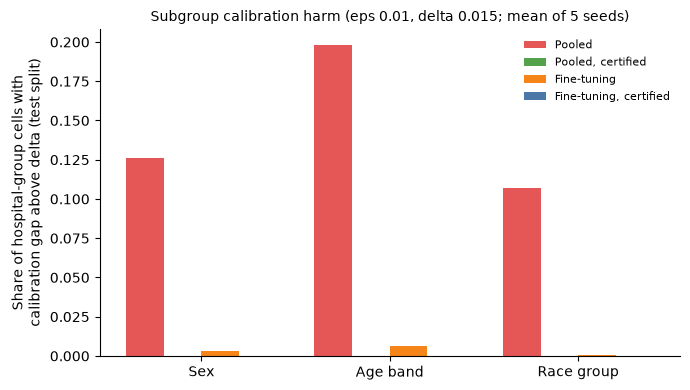

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
os.makedirs("../outputs/figures", exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
seeds = [110, 111, 112, 113, 114]
G = pd.concat([pd.read_csv(f"../outputs/tables/cert_groups_seed{s}.csv") for s in seeds], ignore_index=True)
BN = pd.concat([pd.read_csv(f"../outputs/tables/cert_bins_seed{s}.csv") for s in seeds], ignore_index=True)
EPS_, DEL_ = 0.01, 0.015
M = {"Pooled": "pool_full", "Pooled, certified": f"cert_pool_e{EPS_}_d{DEL_}",
     "Fine-tuning": "ft_full", "Fine-tuning, certified": f"cert_ft_e{EPS_}_d{DEL_}"}
COL = ["#E45756", "#54A24B", "#F58518", "#4C78A8"]
def save(name):
    plt.tight_layout(); plt.savefig(f"../outputs/figures/{name}.png", dpi=300); plt.savefig(f"../outputs/figures/{name}.pdf"); plt.show()

mg = G[G.kind == "marginal"]
rows = []
for var in ["gender", "age_band", "race_grp"]:
    for name, m in M.items():
        t = mg[(mg["var"] == var) & (mg.method == m)]
        ps = t.groupby("seed").agg(cells=("gap_lb", "size"), sig=("gap_lb", lambda s: int((s > DEL_).sum())),
                                   pt=("gap_point", lambda s: int((s > DEL_).sum())))
        rows.append((var, name, ps.cells.mean(), ps.sig.mean(), ps.sig.max(), ps.pt.mean(), ps.pt.mean() / ps.cells.mean()))
T8 = pd.DataFrame(rows, columns=["group_variable", "method", "cells_tested", "significantly_harmed_mean", "significantly_harmed_max",
                                 "point_above_delta_mean", "point_above_delta_share"])
T8.to_csv("../outputs/tables/T8_subgroup_calibration.csv", index=False)
print(T8.round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
w = 0.2
for i, (name, c) in enumerate(zip(M, COL)):
    v = [T8[(T8.group_variable == var) & (T8.method == name)].point_above_delta_share.values[0] for var in ["gender", "age_band", "race_grp"]]
    ax.bar(np.arange(3) + (i - 1.5) * w, v, w, label=name, color=c)
ax.set_xticks(range(3)); ax.set_xticklabels(["Sex", "Age band", "Race group"])
ax.set_ylabel("Share of hospital-group cells with\ncalibration gap above delta (test split)")
ax.set_title(f"Subgroup calibration harm (eps {EPS_}, delta {DEL_}; mean of 5 seeds)", fontsize=10)
ax.legend(frameon=False, fontsize=8)
save("fig7_subgroup_calibration")

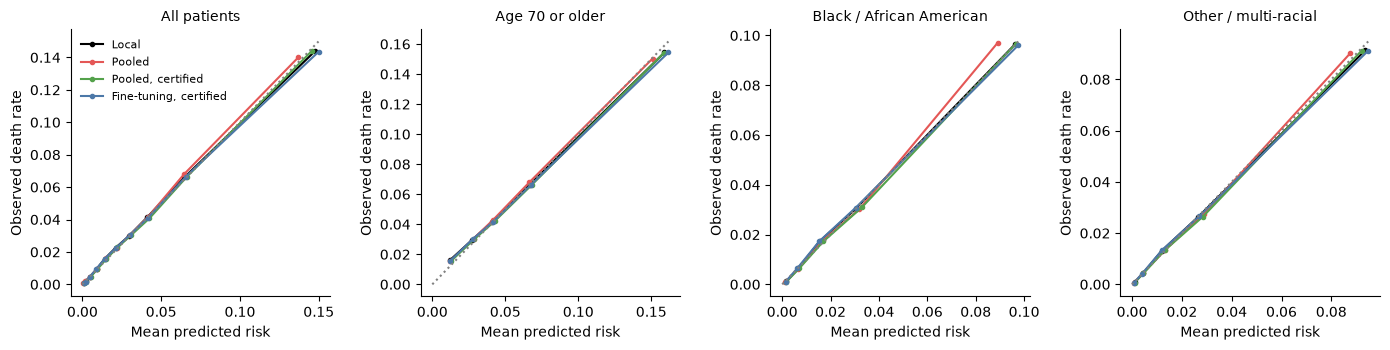

In [2]:
def curve(df):
    g = df.assign(wp=df.n * df.mean_p, wy=df.n * df.mean_y).groupby("bin")[["n", "wp", "wy"]].sum()
    return g.wp / g.n, g.wy / g.n

panels = [("overall", "all", "All patients"), ("age_band", "70 or Older", "Age 70 or older"),
          ("race_grp", "Black/African American", "Black / African American"), ("race_grp", "Other/Multi", "Other / multi-racial")]
bm = {"local": "Local", "pool_full": "Pooled", f"cert_pool_e{EPS_}_d{DEL_}": "Pooled, certified", f"cert_ft_e{EPS_}_d{DEL_}": "Fine-tuning, certified"}
bc = {"local": "k", "pool_full": "#E45756", f"cert_pool_e{EPS_}_d{DEL_}": "#54A24B", f"cert_ft_e{EPS_}_d{DEL_}": "#4C78A8"}
fig, ax = plt.subplots(1, 4, figsize=(14, 3.6))
for a, (var, lev, title) in zip(ax, panels):
    sub = BN[(BN["var"] == var) & (BN.level == lev)]
    mx = 0
    for m, lab in bm.items():
        x, yv = curve(sub[sub.method == m])
        a.plot(x, yv, "o-", ms=3, label=lab, color=bc[m]); mx = max(mx, x.max(), yv.max())
    a.plot([0, mx], [0, mx], ":", c="grey"); a.set_title(title, fontsize=10)
    a.set_xlabel("Mean predicted risk"); a.set_ylabel("Observed death rate")
ax[0].legend(frameon=False, fontsize=8)
save("fig8_reliability")

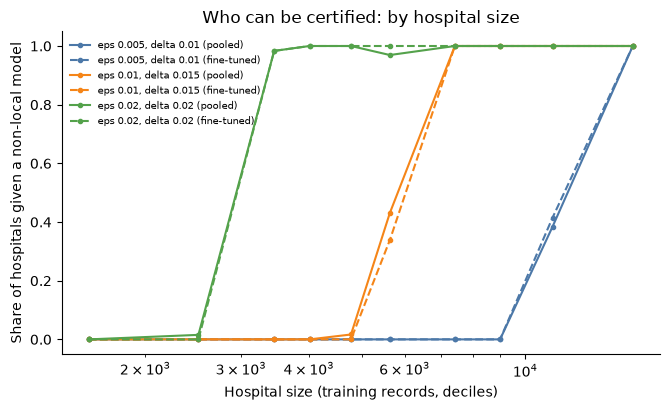

     eps  delta sequence  nonlocal_mean  smallest_certified_n_train  median_certified_n_train
0  0.005  0.010     pool             17                       10255                   14108.0
1  0.005  0.010       ft             17                       11208                   14108.0
2  0.010  0.015     pool             55                        5044                    9541.0
3  0.010  0.015       ft             54                        5745                    9541.0
4  0.020  0.020     pool             99                        2449                    6942.0
5  0.020  0.020       ft             99                        2908                    6942.0


In [3]:
R = pd.concat([pd.read_csv(f"../outputs/tables/cert_full_seed{s}.csv", usecols=lambda c: c in ("hospital", "n_train") or c.endswith("__blend")).assign(seed=s)
               for s in seeds], ignore_index=True).copy()
R["dec"] = pd.qcut(R.n_train, 10, labels=False)
pairs = [(0.005, 0.01), (0.01, 0.015), (0.02, 0.02)]
fig, ax = plt.subplots(figsize=(6.8, 4.2))
rows = []
for (eps, delta), c in zip(pairs, ["#4C78A8", "#F58518", "#54A24B"]):
    for src, ls in (("pool", "-"), ("ft", "--")):
        col = f"cert_{src}_e{eps}_d{delta}__blend"
        share = (R[col] > 0).groupby(R["dec"]).mean(); xm = R.groupby("dec").n_train.median()
        ax.plot(xm, share, ls, color=c, marker="o", ms=3, label=f"eps {eps}, delta {delta} ({'pooled' if src == 'pool' else 'fine-tuned'})")
        nl = R[R[col] > 0]
        rows.append((eps, delta, src, int((R[col] > 0).groupby(R.seed).sum().mean()), nl.n_train.min() if len(nl) else np.nan,
                     nl.n_train.median() if len(nl) else np.nan))
ax.set_xscale("log"); ax.set_xlabel("Hospital size (training records, deciles)"); ax.set_ylabel("Share of hospitals given a non-local model")
ax.legend(frameon=False, fontsize=7); ax.set_title("Who can be certified: by hospital size")
save("fig18_certifiable_size")
T22 = pd.DataFrame(rows, columns=["eps", "delta", "sequence", "nonlocal_mean", "smallest_certified_n_train", "median_certified_n_train"])
T22.to_csv("../outputs/tables/T22_min_certified_size.csv", index=False)
print(T22.to_string())

                   method                       groups  cells  significantly_harmed_mean  point_above_delta_share
0                  Pooled  marginal groups (certified)  895.8                        2.0                   0.1460
1                  Pooled   race x age (not certified)  355.4                        4.2                   0.1976
2       Pooled, certified  marginal groups (certified)  895.8                        0.0                   0.0000
3       Pooled, certified   race x age (not certified)  355.4                        0.0                   0.0028
4             Fine-tuning  marginal groups (certified)  895.8                        0.0                   0.0031
5             Fine-tuning   race x age (not certified)  355.4                        0.0                   0.0079
6  Fine-tuning, certified  marginal groups (certified)  895.8                        0.0                   0.0000
7  Fine-tuning, certified   race x age (not certified)  355.4                        0.0

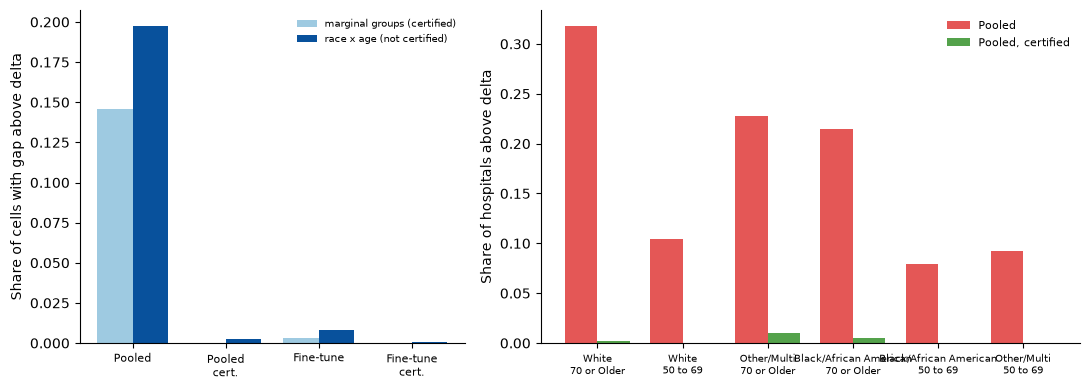

In [4]:
ig = G[G.kind == "intersect"]
rows = []
for name, m in M.items():
    for kind, d in (("marginal groups (certified)", mg), ("race x age (not certified)", ig)):
        t = d[d.method == m]
        ps = t.groupby("seed").agg(c=("gap_lb", "size"), sig=("gap_lb", lambda s: int((s > DEL_).sum())), pt=("gap_point", lambda s: int((s > DEL_).sum())))
        rows.append((name, kind, ps.c.mean(), ps.sig.mean(), (ps.pt / ps.c).mean()))
I = pd.DataFrame(rows, columns=["method", "groups", "cells", "significantly_harmed_mean", "point_above_delta_share"])
I.to_csv("../outputs/tables/T_intersectional.csv", index=False)
print(I.round(4).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.4]})
for i, (kind, c) in enumerate([("marginal groups (certified)", "#9ecae1"), ("race x age (not certified)", "#08519c")]):
    v = [I[(I.method == n) & (I.groups == kind)].point_above_delta_share.values[0] for n in M]
    ax[0].bar(np.arange(4) + (i - 0.5) * 0.38, v, 0.38, label=kind, color=c)
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(["Pooled", "Pooled\ncert.", "Fine-tune", "Fine-tune\ncert."], fontsize=8)
ax[0].set_ylabel("Share of cells with gap above delta"); ax[0].legend(frameon=False, fontsize=7)
lv = ig.groupby("level").size().sort_values(ascending=False).index[:6]
for i, (n, c) in enumerate([("Pooled", "#E45756"), ("Pooled, certified", "#54A24B")]):
    t = ig[(ig.method == M[n]) & (ig.level.isin(lv))].groupby("level").gap_point.apply(lambda s: (s > DEL_).mean()).reindex(lv)
    ax[1].bar(np.arange(len(lv)) + (i - 0.5) * 0.38, t.values, 0.38, label=n, color=c)
ax[1].set_xticks(range(len(lv))); ax[1].set_xticklabels([l.replace("|", "\n") for l in lv], fontsize=7)
ax[1].set_ylabel("Share of hospitals above delta"); ax[1].legend(frameon=False, fontsize=8)
save("fig19_intersectional")

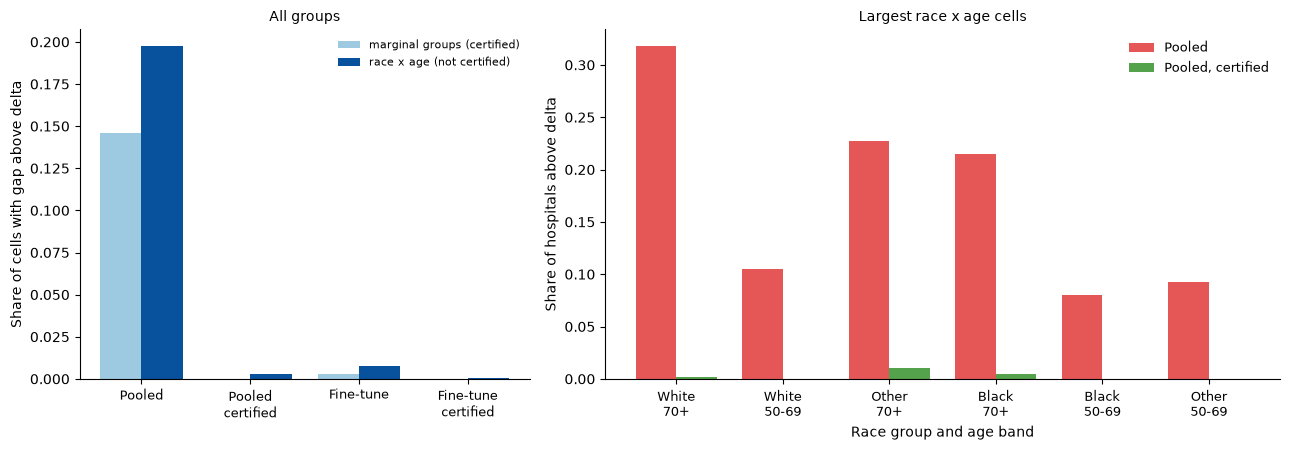

In [5]:
ig = G[G.kind == "intersect"]
short_race = {"White": "White", "Black/African American": "Black", "Other/Multi": "Other"}
short_age = {"70 or Older": "70+", "50 to 69": "50-69", "18-49": "18-49"}
def short(l):
    r, a = l.split("|")
    return f"{short_race.get(r, r)}\n{short_age.get(a, a)}"

rows = []
for name, m in M.items():
    for kind, d in (("marginal groups (certified)", mg), ("race x age (not certified)", ig)):
        t = d[d.method == m]
        ps = t.groupby("seed").agg(c=("gap_lb", "size"), sig=("gap_lb", lambda s: int((s > DEL_).sum())), pt=("gap_point", lambda s: int((s > DEL_).sum())))
        rows.append((name, kind, ps.c.mean(), ps.sig.mean(), (ps.pt / ps.c).mean()))
I = pd.DataFrame(rows, columns=["method", "groups", "cells", "significantly_harmed_mean", "point_above_delta_share"])
I.to_csv("../outputs/tables/T_intersectional.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})
for i, (kind, c) in enumerate([("marginal groups (certified)", "#9ecae1"), ("race x age (not certified)", "#08519c")]):
    v = [I[(I.method == n) & (I.groups == kind)].point_above_delta_share.values[0] for n in M]
    ax[0].bar(np.arange(4) + (i - 0.5) * 0.38, v, 0.38, label=kind, color=c)
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(["Pooled", "Pooled\ncertified", "Fine-tune", "Fine-tune\ncertified"], fontsize=9)
ax[0].set_ylabel("Share of cells with gap above delta"); ax[0].legend(frameon=False, fontsize=8)
ax[0].set_title("All groups", fontsize=10)

lv = list(ig.groupby("level").size().sort_values(ascending=False).index[:6])
for i, (n, c) in enumerate([("Pooled", "#E45756"), ("Pooled, certified", "#54A24B")]):
    t = ig[(ig.method == M[n]) & (ig.level.isin(lv))].groupby("level").gap_point.apply(lambda s: (s > DEL_).mean()).reindex(lv)
    ax[1].bar(np.arange(len(lv)) + (i - 0.5) * 0.38, t.values, 0.38, label=n, color=c)
ax[1].set_xticks(range(len(lv))); ax[1].set_xticklabels([short(l) for l in lv], fontsize=9)
ax[1].set_xlabel("Race group and age band"); ax[1].set_ylabel("Share of hospitals above delta")
ax[1].set_title("Largest race x age cells", fontsize=10); ax[1].legend(frameon=False, fontsize=9)
save("fig19_intersectional")